# Лабораторная работа №1.2. Регрессионный анализ

Отчёт для защиты. Все файлы этой работы лежат в одной папке: данные `data_clean.csv`, расчёт `lab2_regression.py`, рисунки `figures/`. Ноутбук запускается из этой же папки, ячейки идут сверху вниз.

Цель по методичке: изучение регрессионного анализа.

Графики ниже уже встроены в файл. Ниже каждый график стоит отдельно. Перед кодом — что на нём смотреть и какая формула его строит. Под графиком — что на нём получилось и какой из этого вывод.


## Данные и обозначения

Зависимая переменная \(Y\): `price`, арендная плата, USD в месяц.  
Независимые: `bedrooms` (число спален), `square_feet` (площадь, кв. футы), `pets_yes` (фиктивная: 1 — с животными можно, 0 — нельзя).

`pets_allowed` в объявлениях — текст. В регрессию идёт одна фиктивная переменная. Вторую колонку «нельзя» добавлять нельзя: вместе со свободным членом столбцы стали бы линейно зависимы.

Выборка после очистки в ЛР 1.1: \(n = 99602\). Цена в файле целая, но по смыслу это плата, а не число событий.


In [1]:
from pathlib import Path
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from IPython.display import display

BASE = Path(r"d:/МАД/2LAB_MAD")
assert (BASE / "data_clean.csv").exists(), "Нужна папка лабораторной 1.2 с data_clean.csv"
assert (BASE / "lab2_regression.py").exists()

ALPHA = 0.05
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["font.size"] = 11

df = pd.read_csv(BASE / "data_clean.csv")
df["pets_yes"] = df["pets_yes"].astype(int)
y = df["price"].astype(float)
n = len(df)
print(f"n = {n}")
print("столбцы:", list(df.columns))
display(df.head())
pets = df["pets_yes"].value_counts().rename("count").to_frame()
pets["доля"] = pets["count"] / n
display(pets)


n = 99602
столбцы: ['price', 'bedrooms', 'square_feet', 'pets_allowed', 'pets_yes', 'pets_label']


,price,bedrooms,square_feet,pets_allowed,pets_yes,pets_label
0,2195.0,1.0,542.0,Cats,1,да
1,1250.0,3.0,1500.0,"Cats,Dogs",1,да
2,1395.0,3.0,1650.0,NaN,0,нет
3,1600.0,2.0,820.0,"Cats,Dogs",1,да
4,975.0,1.0,624.0,"Cats,Dogs",1,да


,count,доля
pets_yes,,
0,60453,0.606946
1,39149,0.393054


## Пункт 2. Описательные числа и нормальность

Для `price`, `bedrooms`, `square_feet` код считает среднее, стандартное отклонение, квартили, асимметрию и эксцесс Фишера (у нормального закона эксцесс равен 0).

Критерий Жарка–Бера. \(H_0\): выборка взята из нормального распределения. При \(\alpha = 0{,}05\) гипотеза отвергается, если p-value меньше 0,05.

\[
JB = \frac{n}{6}\left(S^2 + \frac{K^2}{4}\right)
\]

\(S\) — асимметрия, \(K\) — эксцесс Фишера. При нормальности JB приблизительно имеет распределение \(\chi^2\) с 2 степенями свободы. В коде это `scipy.stats.jarque_bera`, как в функции `points_1_to_3` файла `lab2_regression.py`.


In [2]:
cols = ["price", "bedrooms", "square_feet"]
desc = df[cols].describe().T
desc["асимметрия"] = df[cols].skew()
desc["эксцесс"] = df[cols].kurtosis()
display(desc)

rows = []
for col in cols:
    x = df[col].to_numpy(dtype=float)
    jb, jp = stats.jarque_bera(x)
    rows.append({
        "переменная": col,
        "асимметрия": float(stats.skew(x)),
        "эксцесс": float(stats.kurtosis(x)),
        "Жарк–Бера": float(jb),
        "p-value": float(jp),
        "нормальна при 0.05": bool(jp >= ALPHA),
    })
display(pd.DataFrame(rows))


,count,mean,std,min,25%,50%,75%,max,асимметрия,эксцесс
price,99602.0,1515.310737,759.252884,100.0,1014.0,1350.0,1795.0,10000.0,2.475397,12.638706
bedrooms,99602.0,1.726190,0.745078,0.0,1.0,2.0,2.0,8.0,0.839965,1.362641
square_feet,99602.0,953.135529,346.418940,101.0,730.0,900.0,1115.0,4970.0,2.315622,12.860035


,переменная,асимметрия,эксцесс,Жарк–Бера,p-value,нормальна при 0.05
0,price,2.475360,12.638011,764565.546971,0.0,False
1,bedrooms,0.839952,1.362512,19416.240371,0.0,False
2,square_feet,2.315587,12.859330,775277.607795,0.0,False


У цены среднее 1515 выше медианы 1350, асимметрия около 2,5, эксцесс около 12,6. У площади та же правосторонняя форма: среднее 953, медиана 900. У спален среднее 1,73, почти все значения — 1 или 2. У всех трёх переменных p-value Жарка–Бера равно 0: с нормальным законом они не согласуются.

Это не запрещает линейную регрессию. Нормальность нужна остаткам, и то в первую очередь для точных t- и F-критериев в малой выборке. Пуассоновскую модель из-за этого провала не выбирают: её выбирают, когда Y — счётчик событий.


## График 1. Гистограмма арендной платы

Гистограмма показывает, как часто цена попадает в равные интервалы. Число интервалов и их длина — формула Стерджесса, функция `sturges_bins`:

\[
k = \mathrm{round}\bigl(1 + 3{,}322 \cdot \lg n\bigr), \qquad h = \frac{\max - \min}{k}.
\]

Для \(n = 99602\): \(\lg 99602 \approx 4{,}9983\), \(1 + 3{,}322 \cdot 4{,}9983 = 17{,}604\), после округления \(k = 18\).

Для цены \(\max = 10000\), \(\min = 100\):

\[
h = \frac{10000 - 100}{18} = 550 \text{ USD}.
\]

`ax.hist(..., bins=k)` режет отрезок от минимума до максимума на 18 столбцов одинаковой ширины. Высота столбца — число объявлений.


price: k = 18, h = 550.0000 USD


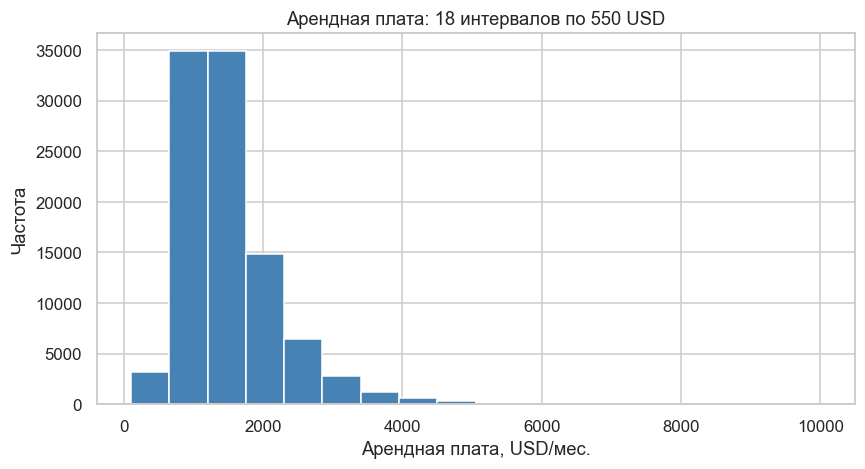

In [3]:
k_price = max(1, int(round(1 + 3.322 * math.log10(n))))
h_price = (y.max() - y.min()) / k_price
print(f"price: k = {k_price}, h = {h_price:.4f} USD")

fig, ax = plt.subplots(figsize=(8, 4.4))
ax.hist(y, bins=k_price, color="steelblue", edgecolor="white")
ax.set_title(f"Арендная плата: {k_price} интервалов по {h_price:.0f} USD")
ax.set_xlabel("Арендная плата, USD/мес.")
ax.set_ylabel("Частота")
fig.tight_layout()
plt.show()


![график](../2LAB_MAD/figures/nb/01.png)

Основная масса объявлений сидит в первых столбцах, примерно до 2000–2500 USD. Дальше столбцы быстро падают, отдельные цены дотягиваются до 10 000. Это тот же правый хвост, что дали асимметрия 2,48 и эксцесс 12,6. Среднее 1515 вытягивают редкие дорогие объекты, медиана 1350 ближе к типичному объявлению.

Для регрессии хвост важен заранее: дорогие квартиры станут большими положительными остатками, и разброс ошибок на правом краю будет шире, чем у дешёвых.


## График 2. Гистограмма площади

Та же формула Стерджесса, те же \(k = 18\), другая длина интервала:

\[
h = \frac{4970 - 101}{18} = \frac{4869}{18} = 270{,}5 \text{ кв. фута}.
\]

Столбцы снова равной ширины. По горизонтали — площадь, по вертикали — число объявлений.


square_feet: k = 18, h = 270.5000


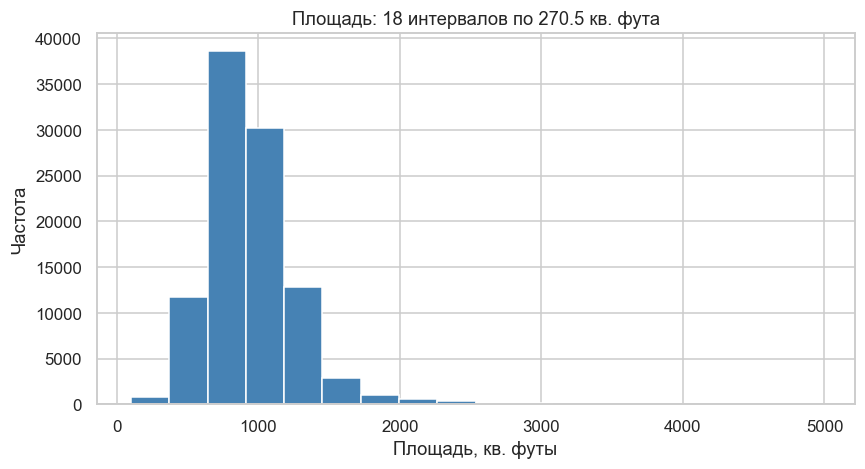

In [4]:
sq = df["square_feet"].astype(float)
k_sq = max(1, int(round(1 + 3.322 * math.log10(n))))
h_sq = (sq.max() - sq.min()) / k_sq
print(f"square_feet: k = {k_sq}, h = {h_sq:.4f}")

fig, ax = plt.subplots(figsize=(8, 4.4))
ax.hist(sq, bins=k_sq, color="steelblue", edgecolor="white")
ax.set_title(f"Площадь: {k_sq} интервалов по {h_sq:.1f} кв. фута")
ax.set_xlabel("Площадь, кв. футы")
ax.set_ylabel("Частота")
fig.tight_layout()
plt.show()


![график](../2LAB_MAD/figures/nb/02.png)

Пик приходится на интервал около 700–1000 кв. футов, медиана площади 900. Хвост тянется к 4970, но таких квартир мало. Форма похожа на цену: большинство объектов компактные, редкие большие тянут среднее (953) выше медианы. Связь «площадь → цена» дальше оценивается именно на этом скошенном фоне, а не на симметричном колоколе.


## График 3. Гистограмма числа спален

Формула Стерджесса формально даёт тот же \(k = 18\) и дробный шаг

\[
h = \frac{8 - 0}{18} = 0{,}444.
\]

Так строить гистограмму нельзя: спальни — целые числа от 0 до 8, различных значений 9. Шаг 0,444 разрезал бы «1» и «2» по разным столбцам. В `points_1_to_3` для спален формула только сообщается, а рисунок строится по целым. Границы столбцов:

\[
-0{,}5,\ 0{,}5,\ 1{,}5,\ \ldots,\ 8{,}5,
\]

то есть `np.arange(min - 0.5, max + 1.5, 1)`. Столбец стоит ровно на каждом целом значении, высота — число квартир с таким числом спален.


Стерджесс дал бы k = 18, h = 0.4444. Различных значений: 9 (от 0 до 8).
На графике столбцы по целым, не по дроби 0.44.


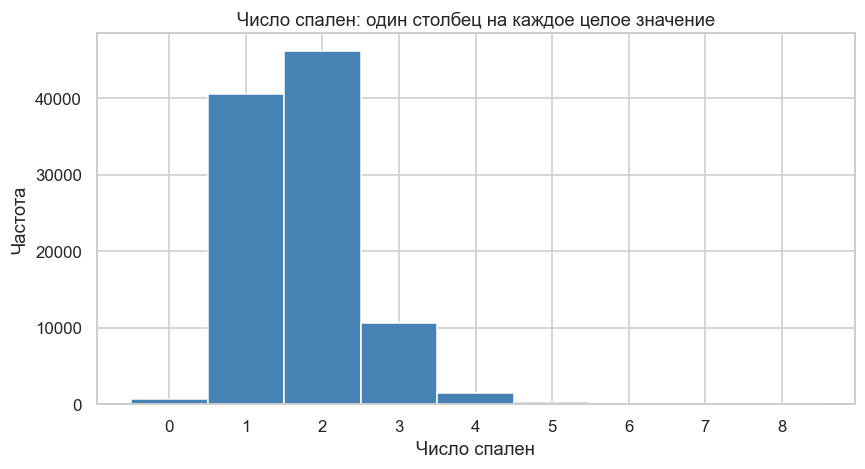

In [5]:
bed = df["bedrooms"].astype(float)
k_bed_formula = max(1, int(round(1 + 3.322 * math.log10(n))))
h_bed_formula = (bed.max() - bed.min()) / k_bed_formula
print(
    f"Стерджесс дал бы k = {k_bed_formula}, h = {h_bed_formula:.4f}. "
    f"Различных значений: {int(bed.nunique())} (от {bed.min():.0f} до {bed.max():.0f})."
)
print("На графике столбцы по целым, не по дроби 0.44.")

edges = np.arange(bed.min() - 0.5, bed.max() + 1.5, 1)
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.hist(bed, bins=edges, color="steelblue", edgecolor="white")
ax.set_title("Число спален: один столбец на каждое целое значение")
ax.set_xlabel("Число спален")
ax.set_ylabel("Частота")
ax.set_xticks(range(int(bed.min()), int(bed.max()) + 1))
fig.tight_layout()
plt.show()


![график](../2LAB_MAD/figures/nb/03.png)

Почти вся выборка — это 1 спальня (около 40 тысяч) и 2 спальни (около 46 тысяч). Ноль спален и 4 и больше встречаются редко, 8 — единицы. Поэтому среднее 1,73 лежит между единицей и двойкой, а не описывает «типичные апартаменты на 8 комнат». В регрессии наклон по спальням оценивается в основном на переходе от 1 к 2 и к 3, крайние значения почти не влияют на форму связи, но могут дать отдельные большие остатки.


## Пункт 4. Какую модель брать дальше

В этом пункте выбор только между линейной и пуассоновской регрессией. Нелинейная появится в пункте 12, здесь её нет. Функция `point_4` ничего не оценивает, она фиксирует правило выбора: смотреть на тип \(Y\).

Линейная модель, метод наименьших квадратов:

\[
E[Y \mid X] = \beta_0 + \beta_1 bedrooms + \beta_2 square\_feet + \beta_3 pets\_yes.
\]

Пуассоновская модель — для неотрицательного целого числа событий. Среднее связано с признаками через логарифм, дисперсия по предпосылке равна среднему:

\[
\log \mu = X\beta, \qquad \mu = \exp(X\beta), \qquad Var(Y) = \mu.
\]

`price` — плата от 100 до 10 000 USD, среднее 1515. Это не число заявок и не число аварий. Для пунктов 5–10 берётся линейная модель. Пуассон всё равно будет построен в пункте 11, потому что задание просит его отдельно.


## Формулы линейной модели, по которым строятся следующие графики

Матрица \(X\) содержит столбец единиц и три признака. `sm.OLS(y, X).fit()` находит

\[
\hat\beta = (X^\top X)^{-1} X^\top y,
\]

это минимум суммы квадратов \(e_i = y_i - \hat y_i\).

Доля объяснённой дисперсии и её вариант со штрафом за лишние признаки:

\[
R^2 = 1 - \frac{\sum e_i^2}{\sum (y_i - \bar y)^2}, \qquad
R^2_{adj} = 1 - (1 - R^2)\frac{n - 1}{n - k - 1}.
\]

Значимость всего уравнения (\(H_0\): все наклоны нулевые):

\[
F = \frac{R^2 / k}{(1 - R^2)/(n - k - 1)}.
\]

Значимость одного коэффициента: \(t_j = \hat\beta_j / se(\hat\beta_j)\), \(H_0\): \(\beta_j = 0\).

Ошибка прогноза в долларах: \(RMSE = \sqrt{\frac{1}{n}\sum e_i^2}\).

Свободный член делает сумму всех остатков нулевой. Поэтому «среднее остатков равно нулю» само по себе ничего не проверяет. На графике остатков смотрят, не ползёт ли среднее и не раздувается ли ширина облака при росте \(\hat y\).


In [6]:
X_lin = sm.add_constant(df[["bedrooms", "square_feet", "pets_yes"]].astype(float))
lin = sm.OLS(y, X_lin).fit()
b = lin.params
resid_lin = np.asarray(lin.resid, dtype=float)
fitted_lin = np.asarray(lin.fittedvalues, dtype=float)
rmse_lin = float(np.sqrt(np.mean(resid_lin ** 2)))

print(
    f"ŷ = {b['const']:.6f} {b['bedrooms']:+.6f}*bedrooms "
    f"{b['square_feet']:+.6f}*square_feet {b['pets_yes']:+.6f}*pets_yes"
)
print(f"R² = {lin.rsquared:.6f},  R²_adj = {lin.rsquared_adj:.6f}")
print(f"F = {lin.fvalue:.2f},  p = {lin.f_pvalue:.3g},  RMSE = {rmse_lin:.2f} USD")
display(pd.DataFrame({
    "коэффициент": lin.params,
    "ст. ошибка": lin.bse,
    "t": lin.tvalues,
    "p-value": lin.pvalues,
}))


ŷ = 757.301238 -74.857212*bedrooms +0.955403*square_feet -59.537031*pets_yes
R² = 0.152162,  R²_adj = 0.152137
F = 5958.33,  p = 0,  RMSE = 699.10 USD


,коэффициент,ст. ошибка,t,p-value
const,757.301238,6.878027,110.104424,0.000000e+00
bedrooms,-74.857212,4.264669,-17.552879,7.182789e-69
square_feet,0.955403,0.009177,104.104040,0.000000e+00
pets_yes,-59.537031,4.539087,-13.116523,2.854542e-39


Уравнение, которое нужно записать:

\[
\hat y = 757{,}301 - 74{,}857 \cdot bedrooms + 0{,}955 \cdot square\_feet - 59{,}537 \cdot pets\_yes.
\]

\(R^2 = 0{,}1522\), \(F = 5958\) при критическом значении около 2,6, p-value = 0. Уравнение значимо, каждый коэффициент значим (\(|t|\) намного больше 1,96). RMSE около 699 USD при средней цене 1515: модель ловит среднюю связь, а не цену конкретного объявления.

Как читать коэффициенты, когда графики остатков будут уже перед глазами. Плюс 0,955 USD — это прибавка за 1 кв. фут при тех же спальнях и том же флаге животных. Минус 74,9 USD за спальню — частный эффект при фиксированной площади: комнат больше, сами комнаты меньше. Парная корреляция цены и спален при этом положительная (около 0,24), потому что квартир с большим числом спален в среднем больше по площади (корреляция спален и площади около 0,72). Минус 59,5 USD у `pets_yes` — разница объявлений, а не эксперимент «разрешили животных — цена упала». Свободный член 757 — уровень при нулевой площади; такой квартиры в данных нет.


## График 4. Как вообще выглядит график остатков

Это не расчёт по выборке, а три схемы, которые методичка просит уметь отличить. По горизонтали — условное предсказанное значение, по вертикали — остаток. Красная линия — ноль.

1. Удачная модель: \(e \sim N(0, 1)\), полоса одной ширины.
2. Гетероскедастичность: \(e \sim N(0,\ 0{,}3 + 0{,}25 x)\), воронка.
3. Пропущенная кривизна: \(e = (x - 5)^2 / 6 + \text{шум}\), дуга. Среднее остатка зависит от уровня прогноза.

Дальше реальные графики лабораторной сравниваются с этими тремя, а не «на глаз, красиво или нет».


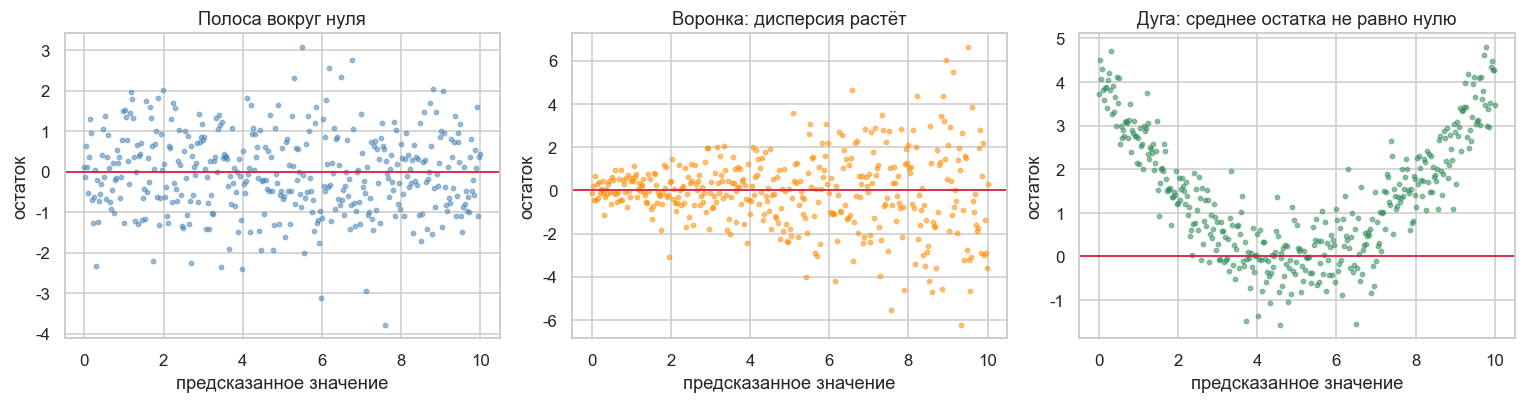

In [7]:
rng_demo = np.random.default_rng(0)
xx = np.linspace(0, 10, 400)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))

axes[0].scatter(xx, rng_demo.normal(0, 1, size=xx.size), s=8, alpha=0.5, c="steelblue")
axes[0].set_title("Полоса вокруг нуля")

axes[1].scatter(xx, rng_demo.normal(0, 0.3 + 0.25 * xx, size=xx.size), s=8, alpha=0.5, c="darkorange")
axes[1].set_title("Воронка: дисперсия растёт")

axes[2].scatter(xx, (xx - 5) ** 2 / 6 + rng_demo.normal(0, 0.6, size=xx.size), s=8, alpha=0.5, c="seagreen")
axes[2].set_title("Дуга: среднее остатка не равно нулю")

for ax in axes:
    ax.axhline(0, color="crimson", lw=1.1)
    ax.set_xlabel("предсказанное значение")
    ax.set_ylabel("остаток")
fig.tight_layout()
plt.show()


![график](../2LAB_MAD/figures/nb/04.png)

Левая схема — то, к чему хотелось бы прийти. Средняя — дисперсия ошибки растёт вместе с прогнозом, тест Бройша–Пагана как раз про это. Правая — в модели не хватает нелинейного члена, остатки систематически положительны по краям и отрицательны в середине. У наших данных, как покажут следующие графики, ближе средняя схема плюс длинный верхний хвост, а не правая дуга.


## График 5. Остатки линейной модели

Каждая точка — одно объявление. Координаты:

\[
\hat y_i = x_i^\top \hat\beta, \qquad e_i = y_i - \hat y_i.
\]

По горизонтали прогноз аренды, по вертикали на сколько долларов факт выше или ниже прогноза. Красная линия — ноль. В `plot_residuals` на рисунок попадает случайная подвыборка 8000 точек из 99 602, иначе облако сливается в пятно. Генератор с seed 42, картинка воспроизводима. Все числа под графиком считаются по всем остаткам, урезается только рисунок.

Постоянство среднего проверяют по квартилям \(\hat y\) (`pd.qcut` на 4 группы). В скрипте сдвиг называют малым, если наибольший модуль группового среднего меньше \(0{,}15\, s_e\). Порог 0,15 — правило этого отчёта, не табличный квантиль.

Постоянство дисперсии проверяет тест Бройша–Пагана: квадраты остатков регрессируют на те же \(X\), статистика \(LM = n R^2_{e^2}\). \(H_0\) — дисперсия постоянна. Отношение максимальной групповой дисперсии к минимальной оставляют как наглядное число рядом с тестом.


среднее всех остатков = -1.24e-11 (около нуля из-за свободного члена)
медиана остатков = -158.90
sd(e) = 699.11
наибольший |средний e| по квартилям = 49.17, отношение к sd = 0.070
порог 0.15: сдвиг мал
max/min дисперсий = 2.5047
Бройш–Паган: LM = 3608.03, p = 0


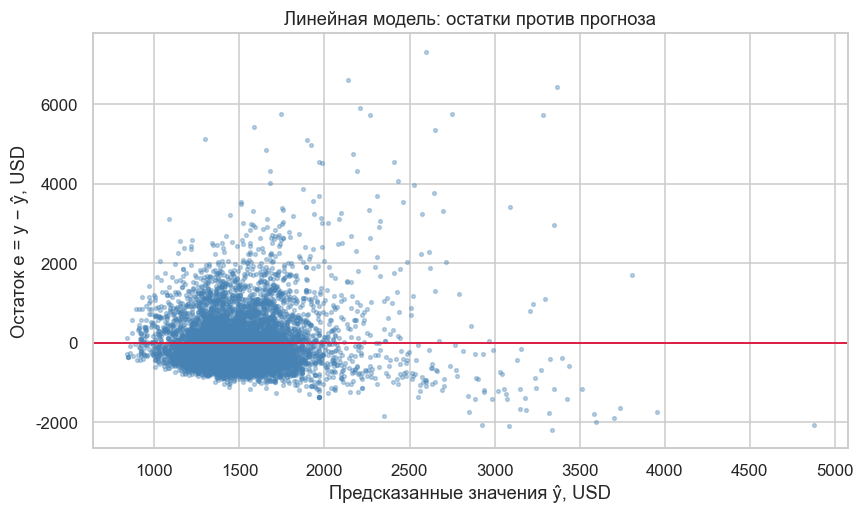

,среднее e,дисперсия e
"(771.9490000000001, 1341.034]",15.886492,339763.889013
"(1341.034, 1472.562]",-44.492505,337135.536388
"(1472.562, 1648.021]",-20.514329,428993.760246
"(1648.021, 5214.858]",49.170196,844426.570619


In [8]:
rng = np.random.default_rng(42)
take = rng.choice(n, size=8000, replace=False)

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.scatter(fitted_lin[take], resid_lin[take], s=6, alpha=0.35, c="steelblue")
ax.axhline(0, color="crimson", lw=1.2)
ax.set_title("Линейная модель: остатки против прогноза")
ax.set_xlabel("Предсказанные значения ŷ, USD")
ax.set_ylabel("Остаток e = y − ŷ, USD")
fig.tight_layout()
plt.show()

q_lin = pd.qcut(fitted_lin, q=4, duplicates="drop")
g_lin = pd.Series(resid_lin).groupby(q_lin, observed=True)
quart_lin = pd.DataFrame({
    "среднее e": g_lin.mean(),
    "дисперсия e": g_lin.var(ddof=1),
})
display(quart_lin)
sd_lin = float(resid_lin.std(ddof=1))
max_abs_lin = float(np.max(np.abs(quart_lin["среднее e"])))
var_ratio_lin = float(quart_lin["дисперсия e"].max() / quart_lin["дисперсия e"].min())
bp_lm_lin, bp_p_lin, _, _ = het_breuschpagan(resid_lin, lin.model.exog)
print(f"среднее всех остатков = {resid_lin.mean():.3g} (около нуля из-за свободного члена)")
print(f"медиана остатков = {np.median(resid_lin):.2f}")
print(f"sd(e) = {sd_lin:.2f}")
print(f"наибольший |средний e| по квартилям = {max_abs_lin:.2f}, отношение к sd = {max_abs_lin / sd_lin:.3f}")
print("порог 0.15:", "сдвиг мал" if max_abs_lin < 0.15 * sd_lin else "сдвиг заметен")
print(f"max/min дисперсий = {var_ratio_lin:.4f}")
print(f"Бройш–Паган: LM = {bp_lm_lin:.2f}, p = {bp_p_lin:.3g}")


![график](../2LAB_MAD/figures/nb/05.png)

Облако густое при прогнозе 1000–2000 USD и редеет к 4000–5000. Вверх точки вылетают до плюс нескольких тысяч долларов: квартира гораздо дороже, чем позволяют площадь и спальни. Вниз облако короче, потому что цена не бывает ниже 100 USD. Дуги, как на правой учебной схеме, нет. Воронка есть: верхняя четверть прогноза заметно шире нижней.

Числа по всем остаткам. Групповые средние примерно +16, −44, −21, +49 USD. Самый большой сдвиг 49 USD при \(s_e \approx 699\), отношение 0,07 < 0,15. Среднее по уровню прогноза можно считать примерно постоянным. Дисперсия в верхней четверти относится к нижней как 2,50 к 1. Бройш–Паган: LM = 3608, p-value = 0, постоянство дисперсии отвергается. Медиана остатка отрицательная при нулевом среднем: много умеренных минусов уравновешиваются редкими большими плюсами.

Вывод по графику: линейная формула не оставила систематической дуги, но разброс ошибки больше в дорогом сегменте. Это гетероскедастичность, средняя из трёх учебных схем.


## График 6. Гистограмма стандартизированных остатков линейной модели

Стандартизация делит остаток на его выборочное стандартное отклонение, как `standardized_residuals`:

\[
e_i^{st} = \frac{e_i}{s_e}, \qquad
s_e = \sqrt{\frac{1}{n-1}\sum_{i=1}^{n}(e_i - \bar e)^2}.
\]

Гистограмма строится по плотности (`density=True`), 40 столбцов, на неё наложена кривая \(N(0, 1)\):

\[
\varphi(z) = \frac{1}{\sqrt{2\pi}}\exp\left(-\frac{z^2}{2}\right).
\]

Если бы остатки были нормальными с нулевым средним, столбцы легли бы на красную кривую. В скрипте ориентир симметрии — модуль асимметрии меньше 0,5. Это ориентир, не отдельный критерий согласия.


асимметрия = 2.1620
эксцесс = 9.8458


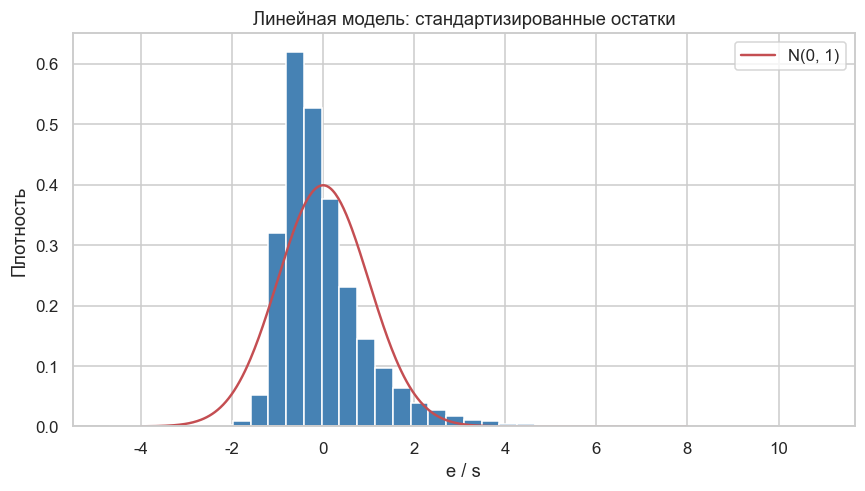

In [9]:
std_lin = resid_lin / resid_lin.std(ddof=1)
print(f"асимметрия = {pd.Series(std_lin).skew():.4f}")
print(f"эксцесс = {pd.Series(std_lin).kurtosis():.4f}")

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.hist(std_lin, bins=40, color="steelblue", edgecolor="white", density=True)
xs = np.linspace(-4, 8, 400)
ax.plot(xs, stats.norm.pdf(xs), "r-", lw=1.6, label="N(0, 1)")
ax.set_title("Линейная модель: стандартизированные остатки")
ax.set_xlabel("e / s")
ax.set_ylabel("Плотность")
ax.legend()
fig.tight_layout()
plt.show()


![график](../2LAB_MAD/figures/nb/06.png)

Пик стоит чуть левее нуля и выше нормальной кривой. Вправо тянется хвост до 8–10 стандартных отклонений, влево обрыв около −3. Асимметрия 2,16, эксцесс 9,85. С \(N(0, 1)\) гистограмма не совпадает.

Вместе графики 5 и 6 закрывают пункты 6, 7 и 9 для линейной модели. \(R^2 = 0{,}152\): объяснено 15% разброса цены, 85% остаются в остатке. Среднее остатков по уровню \(\hat y\) примерно постоянно, дисперсия не постоянна, нормальность остатков не выполняется. Уравнение при этом значимо (пункт 10): \(F = 5958\), p-value = 0, все t-критерии далеки от 1,96. Значимость и качество здесь расходятся, потому что \(n = 99602\): слабая связь обнаруживается надёжно и всё равно объясняет мало.


## Пункт 11. Пуассоновская модель: формулы перед её графиками

Те же три признака. Y округляется до неотрицательного целого (`np.rint` и обрезка снизу нулём), потому что правдоподобие Пуассона определено на таких числах. В этом файле цена уже целая и положительная, преобразование ничего не меняет.

Оценка — максимальное правдоподобие, `sm.GLM(..., family=Poisson)`, не МНК:

\[
\log \mu = \beta_0 + \beta_1 bedrooms + \beta_2 square\_feet + \beta_3 pets\_yes, \qquad \mu = \exp(\log \mu).
\]

Коэффициент \(\beta_j\) — не доллары. Прирост признака на 1 умножает среднюю цену на \(e^{\beta_j}\).

Классический Пуассон требует \(Var(Y) = \mu\). Проверка:

\[
\varphi = \frac{1}{n - k - 1}\sum_i \frac{(y_i - \hat\mu_i)^2}{\hat\mu_i}.
\]

Нужно \(\varphi \approx 1\). Если \(\varphi\) сильно больше 1, обычные z и отношение правдоподобия завышены. В `evaluate_glm_poisson` стандартные ошибки умножают на \(\sqrt{\varphi}\), а значимость уравнения берут по квази-LR:

\[
LR = 2(\ell_{model} - \ell_{null}), \qquad \text{квази-LR} = LR / \varphi.
\]

Квази-LR сравнивают с \(\chi^2\) на \(k = 3\) степенях свободы. Сырой LR в вывод не идёт.

Рядом с линейным \(R^2\) ставят дисперсионный, в тех же единицах:

\[
R^2_{var} = 1 - \frac{\sum (y_i - \hat\mu_i)^2}{\sum (y_i - \bar y)^2}.
\]

Псевдо-\(R^2\) Макфаддена \(1 - \ell_{model}/\ell_{null}\) — про правдоподобие, его с линейным \(R^2\) не сравнивают. RMSE считают по сырым остаткам \(y - \hat\mu\), в долларах.


In [10]:
y_pois = np.clip(np.rint(y.to_numpy()), 0, None).astype(float)
X_pois = sm.add_constant(df[["bedrooms", "square_feet", "pets_yes"]].astype(float))
pois = sm.GLM(y_pois, X_pois, family=sm.families.Poisson()).fit()
null = sm.GLM(y_pois, np.ones((n, 1)), family=sm.families.Poisson()).fit()

mu = np.asarray(pois.fittedvalues, dtype=float)
resid_pois = y_pois - mu
k_pois = int(pois.df_model)
phi = float(np.sum(np.asarray(pois.resid_pearson) ** 2) / pois.df_resid)
lr_stat = 2 * (float(pois.llf) - float(null.llf))
lr_quasi = lr_stat / phi
lr_quasi_p = float(stats.chi2.sf(lr_quasi, k_pois))
ss_res = float(np.sum(resid_pois ** 2))
ss_tot = float(np.sum((y_pois - y_pois.mean()) ** 2))
r2_pois = 1 - ss_res / ss_tot
r2_pois_adj = 1 - (1 - r2_pois) * (n - 1) / (n - k_pois - 1)
pseudo_r2 = 1 - float(pois.llf) / float(null.llf)
rmse_pois = float(np.sqrt(np.mean(resid_pois ** 2)))
se_quasi = pois.bse * math.sqrt(phi)
z_quasi = pois.params / se_quasi
p_quasi = 2 * stats.norm.sf(np.abs(z_quasi.to_numpy(dtype=float)))

bp = pois.params
print(
    f"log(μ) = {bp['const']:.6f} {bp['bedrooms']:+.6f}*bedrooms "
    f"{bp['square_feet']:+.6f}*square_feet {bp['pets_yes']:+.6f}*pets_yes"
)
print(f"при всех X = 0 среднее μ = exp({bp['const']:.4f}) = {math.exp(bp['const']):.1f} USD")
display(pd.DataFrame({
    "коэффициент": pois.params,
    "se при φ=1": pois.bse,
    "se квази": se_quasi,
    "z квази": z_quasi,
    "p квази": p_quasi,
}))
print(f"φ = {phi:.2f}, √φ = {math.sqrt(phi):.2f}")
print(f"LR при φ=1 (не используется) = {lr_stat:.1f}")
print(f"квази-LR = {lr_quasi:.2f}, p = {lr_quasi_p:.3g}")
print(f"R² по дисперсии = {r2_pois:.6f}, R²_adj = {r2_pois_adj:.6f}")
print(f"псевдо-R² Макфаддена = {pseudo_r2:.6f}")
print(f"RMSE = {rmse_pois:.2f} USD")
print("процентное изменение среднего при +1 к признаку, 100*(exp(β)-1):")
for name in ["bedrooms", "square_feet", "pets_yes"]:
    print(f"  {name}: {100 * (math.exp(bp[name]) - 1):+.3f}%")


log(μ) = 6.912634 -0.025002*bedrooms +0.000478*square_feet -0.039364*pets_yes
при всех X = 0 среднее μ = exp(6.9126) = 1004.9 USD
φ = 307.09, √φ = 17.52
LR при φ=1 (не используется) = 4926617.7
квази-LR = 16042.66, p = 0
R² по дисперсии = 0.135155, R²_adj = 0.135129
псевдо-R² Макфаддена = 0.151572
RMSE = 706.08 USD
процентное изменение среднего при +1 к признаку, 100*(exp(β)-1):
  bedrooms: -2.469%
  square_feet: +0.048%
  pets_yes: -3.860%


,коэффициент,se при φ=1,se квази,z квази,p квази
const,6.912634,2.278505e-04,0.003993,1731.239921,0.000000e+00
bedrooms,-0.025002,1.492811e-04,0.002616,-9.557447,1.206976e-21
square_feet,0.000478,2.747102e-07,0.000005,99.270788,0.000000e+00
pets_yes,-0.039364,1.679458e-04,0.002943,-13.374992,8.466275e-41


Уравнение:

\[
\log \hat\mu = 6{,}91263 - 0{,}02500 \cdot bedrooms + 0{,}000478 \cdot square\_feet - 0{,}03936 \cdot pets\_yes.
\]

\(\varphi = 307\). Дисперсия цены в сотни раз больше пуассоновской предпосылки «дисперсия равна среднему»: при средней плате около 1500 пуассоновское стандартное отклонение было бы около 39 USD, фактическое — 759. Поэтому в таблице значимости смотрят квази-z, а не сырые ошибки. Квази-LR около 16043, p-value = 0, уравнение значимо и после поправки. Знаки те же, что у линейной модели.

В процентах на единицу признака: спальня около −2,5%, квадратный фут около +0,048%, разрешение животных около −3,9%. В долларах эффект зависит от уровня \(\mu\), потому что \(\partial \mu / \partial x_j = \beta_j \mu\). На цене 1515 USD это примерно −38 USD за спальню, +0,72 USD за фут и −60 USD за животных. Свободный член 6,913 — логарифм, само \(\mu\) при нулевых X около 1005 USD. С линейными 757 USD его не сравнивают.


## График 7. Остатки пуассоновской модели

Остаток снова в долларах, иначе с линейной моделью не сравнить:

\[
e_i = y_i - \hat\mu_i.
\]

По горизонтали уже не линейный прогноз, а пуассоновское среднее \(\hat\mu = \exp(x^\top \hat\beta)\). Красная линия — ноль. На рисунке те же 8000 случайных точек, статистики — по всей выборке. Квартили, порог 0,15 и Бройш–Паган считаются так же, как для графика 5.


sd(e) = 706.08
наибольший |средний e| = 83.05, отношение к sd = 0.118
max/min дисперсий = 2.6374
Бройш–Паган: LM = 5167.14, p = 0


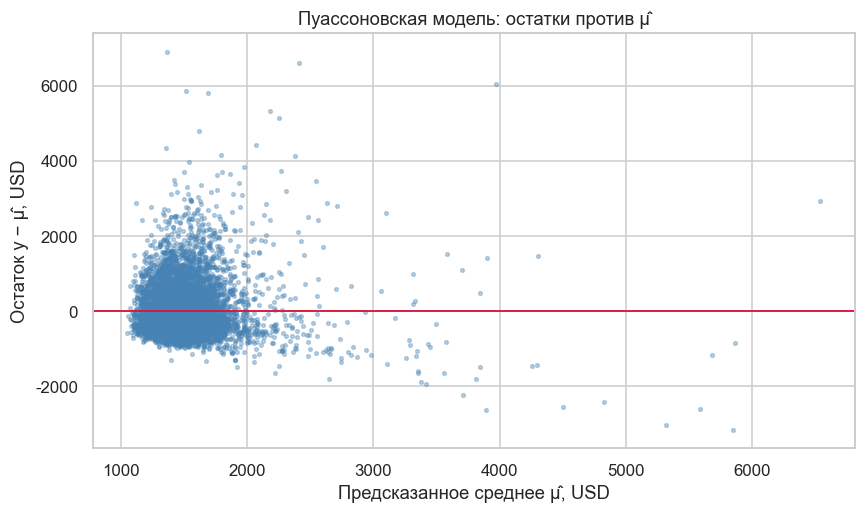

,среднее e,дисперсия e
"(1015.177, 1361.163]",-38.493127,333281.317588
"(1361.163, 1462.687]",-46.362410,337291.677877
"(1462.687, 1604.904]",1.813349,434234.147999
"(1604.904, 9725.49]",83.052818,878996.011542


In [11]:
take_p = rng.choice(n, size=8000, replace=False)
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.scatter(mu[take_p], resid_pois[take_p], s=6, alpha=0.35, c="steelblue")
ax.axhline(0, color="crimson", lw=1.2)
ax.set_title("Пуассоновская модель: остатки против μ̂")
ax.set_xlabel("Предсказанное среднее μ̂, USD")
ax.set_ylabel("Остаток y − μ̂, USD")
fig.tight_layout()
plt.show()

q_p = pd.qcut(mu, 4, duplicates="drop")
g_p = pd.Series(resid_pois).groupby(q_p, observed=True)
quart_p = pd.DataFrame({"среднее e": g_p.mean(), "дисперсия e": g_p.var(ddof=1)})
display(quart_p)
sd_p = float(resid_pois.std(ddof=1))
max_abs_p = float(np.max(np.abs(quart_p["среднее e"])))
bp_lm_p, bp_p_p, _, _ = het_breuschpagan(resid_pois, np.asarray(pois.model.exog, dtype=float))
print(f"sd(e) = {sd_p:.2f}")
print(f"наибольший |средний e| = {max_abs_p:.2f}, отношение к sd = {max_abs_p / sd_p:.3f}")
print(f"max/min дисперсий = {quart_p['дисперсия e'].max() / quart_p['дисперсия e'].min():.4f}")
print(f"Бройш–Паган: LM = {bp_lm_p:.2f}, p = {bp_p_p:.3g}")


![график](../2LAB_MAD/figures/nb/07.png)

Картина та же, что у линейной модели, только прогнозы местами уезжают дальше, к 6000–9000 USD. Облако по-прежнему густое слева и редеет вправо, сверху редкие остатки в несколько тысяч долларов. Дуги нет. Воронка есть.

Групповые средние около −38, −46, +2 и +83 USD. Наибольший модуль 83 при sd около 706, отношение 0,12, ещё ниже порога 0,15, но верхняя четверть сдвигается сильнее, чем у линейной модели (там было 49). Отношение дисперсий около 2,64. Бройш–Паган: LM около 5167, p-value = 0. Логарифмическая связь не убрала гетероскедастичность аренды.


## График 8. Стандартизированные остатки пуассоновской модели

Деление то же, только остаток сырой, \(y - \hat\mu\), а не остаток Пирсона \((y - \mu)/\sqrt{\mu}\). Пирсоновский остаток нужен был для \(\varphi\). На гистограмму пункта 7 задания кладут остаток в тех же единицах, что и у линейной модели, чтобы кривую \(N(0, 1)\) читать одинаково:

\[
e_i^{st} = \frac{y_i - \hat\mu_i}{s_e}.
\]


асимметрия = 1.9667
эксцесс = 9.9070


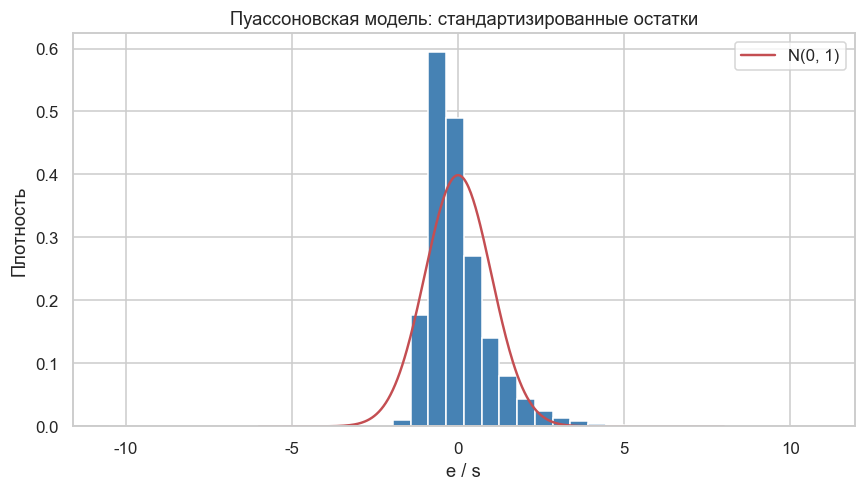

In [12]:
std_pois = resid_pois / resid_pois.std(ddof=1)
print(f"асимметрия = {pd.Series(std_pois).skew():.4f}")
print(f"эксцесс = {pd.Series(std_pois).kurtosis():.4f}")

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.hist(std_pois, bins=40, color="steelblue", edgecolor="white", density=True)
xs = np.linspace(-6, 8, 400)
ax.plot(xs, stats.norm.pdf(xs), "r-", lw=1.6, label="N(0, 1)")
ax.set_title("Пуассоновская модель: стандартизированные остатки")
ax.set_xlabel("e / s")
ax.set_ylabel("Плотность")
ax.legend()
fig.tight_layout()
plt.show()


![график](../2LAB_MAD/figures/nb/08.png)

Снова пик левее нуля и длинный правый хвост. Асимметрия около 1,97, эксцесс около 9,9. Нормальной гистограмма не стала. Пункты 6–7 для Пуассона дают тот же диагноз, что и для линейной модели: среднее по уровню прогноза ещё терпимо, дисперсия не постоянна, остатки скошены.

Качество ниже линейной модели: \(R^2_{var} = 0{,}135\) против 0,152, RMSE 706 против 699. Значимость есть только в квази-смысле. Для аренды Пуассон хуже и по типу Y, и по этим двум графикам, и по ошибке в долларах.


## График 9. Линейная модель против пуассоновской

Столбик — доля дисперсии цены, которую модель сняла. Для линейной это обычный \(R^2\). Для Пуассона — \(R^2_{var}\) из предыдущего раздела, не псевдо-\(R^2\) Макфаддена. Высота подписывается над столбцом. Нелинейной модели на этом графике нет: по заданию она появляется только в пункте 12, сравнение пункта 11 идёт между двумя кандидатами пункта 4.


RMSE линейная 699.10 USD, пуассоновская 706.08 USD
φ пуассоновской модели = 307.09 (для Пуассона нужно около 1)


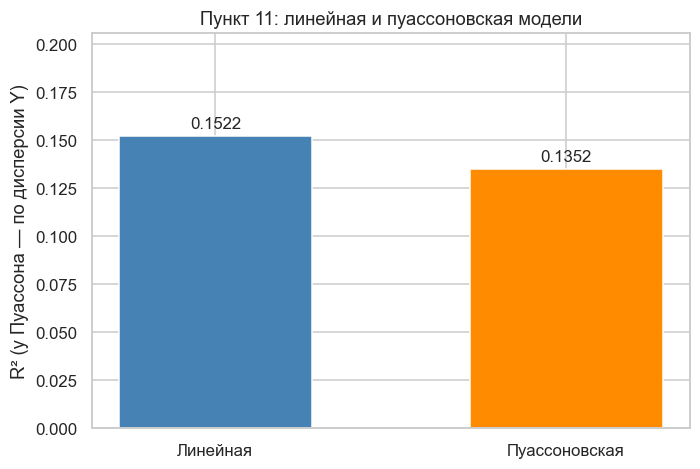

In [13]:
names_lp = ["Линейная", "Пуассоновская"]
vals_lp = [float(lin.rsquared), float(r2_pois)]
fig, ax = plt.subplots(figsize=(6.5, 4.4))
bars = ax.bar(names_lp, vals_lp, color=["steelblue", "darkorange"], width=0.55)
ax.set_ylabel("R² (у Пуассона — по дисперсии Y)")
ax.set_title("Пункт 11: линейная и пуассоновская модели")
ax.set_ylim(0, max(vals_lp) * 1.35)
for bar, val in zip(bars, vals_lp):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 0.004, f"{val:.4f}", ha="center")
fig.tight_layout()
plt.show()
print(f"RMSE линейная {rmse_lin:.2f} USD, пуассоновская {rmse_pois:.2f} USD")
print(f"φ пуассоновской модели = {phi:.2f} (для Пуассона нужно около 1)")


![график](../2LAB_MAD/figures/nb/09.png)

Синий столбец выше оранжевого: 0,152 против 0,135. Разница небольшая на фоне того, что обе модели оставляют больше 85% дисперсии необъяснённой, но она устойчивая: и \(R^2\), и RMSE в пользу линейной (699 против 706 USD). Оранжевый столбец при этом ещё и опирается на невыполненную предпосылку \(\varphi = 307\).

Вывод пункта 11. Выбор пункта 4 подтверждается. Рабочей остаётся линейная модель. Пуассоновская значима по квази-LR, но для арендной платы она формальная и по качеству хуже.


## Пункт 12. Нелинейная модель: формулы перед её графиками

Методичка разрешает линейную свёртку нелинейных элементов и даёт пример \(a_0 x^3 + a_1 x^2 \log x\). Слово «например» — образец приёма, не единственная обязательная формула. В `point_12_nonlinear` площадь \(x = square\_feet\) входит тремя функциями, спальни и фиктивная переменная остаются:

\[
\hat y = \beta_0 + \beta_1 x + \beta_2 x^2 + \beta_3 x^2 \log x + \beta_4 bedrooms + \beta_5 pets\_yes.
\]

Модель нелинейна по площади и линейна по \(\beta\), поэтому её снова оценивает МНК. Логарифм определён: минимальная площадь 101. В коде `np.log` — натуральный логарифм, столбцы называются `square_feet`, `square_feet_sq`, `square_feet_sq_log`.

\(x\), \(x^2\) и \(x^2 \log x\) — три функции одной площади, на узком диапазоне типичных квартир они почти копируют друг друга. VIF признака:

\[
VIF_j = \frac{1}{1 - R^2_j},
\]

где \(R^2_j\) — регрессия этого столбца на остальные. VIF больше 10 считают тяжёлой коллинеарностью. Число обусловленности — отношение крайних сингулярных чисел матрицы \(X\); у устойчивой матрицы оно невелико.

Из-за коллинеарности t-критерии могут отвергать «коэффициент равен нулю», но знак каждого из трёх коэффициентов площади по отдельности не читается. Смотрят прибавку \(R^2\) ко всей тройке. Вложенный критерий на \(q = 2\) новых члена:

\[
F = \frac{(R^2_{new} - R^2_{lin}) / q}{(1 - R^2_{new}) / (n - k_{new} - 1)}.
\]

Порог отчёта другой, практический: если \(R^2_{adj}\) вырос меньше чем на 0,01, усложнение считают бесполезным для вывода. Это не квантиль F.


In [14]:
x = df["square_feet"].astype(float).to_numpy()
design = pd.DataFrame({
    "square_feet": x,
    "square_feet_sq": x ** 2,
    "square_feet_sq_log": (x ** 2) * np.log(x),
    "bedrooms": df["bedrooms"].astype(float).to_numpy(),
    "pets_yes": df["pets_yes"].astype(float).to_numpy(),
})
X_nl = sm.add_constant(design)
nl = sm.OLS(y, X_nl).fit()
resid_nl = np.asarray(nl.resid, dtype=float)
fitted_nl = np.asarray(nl.fittedvalues, dtype=float)
rmse_nl = float(np.sqrt(np.mean(resid_nl ** 2)))

exog = np.asarray(X_nl, dtype=float)
vif = pd.Series(
    {name: float(variance_inflation_factor(exog, i)) for i, name in enumerate(X_nl.columns) if name != "const"},
    name="VIF",
)
display(vif.to_frame())
print(f"число обусловленности = {nl.condition_number:.6g}")
bn = nl.params
print(
    "ŷ = "
    f"{bn['const']:.6f} {bn['square_feet']:+.6f}*x "
    f"{bn['square_feet_sq']:+.6f}*x² "
    f"{bn['square_feet_sq_log']:+.6f}*x²·log(x) "
    f"{bn['bedrooms']:+.6f}*bedrooms {bn['pets_yes']:+.6f}*pets_yes"
)
print(f"R² = {nl.rsquared:.6f}, R²_adj = {nl.rsquared_adj:.6f}")
print(f"F = {nl.fvalue:.2f}, p = {nl.f_pvalue:.3g}, RMSE = {rmse_nl:.2f}")
d_r2 = float(nl.rsquared - lin.rsquared)
q_extra = 2
df_full = n - int(nl.df_model) - 1
F_nested = (d_r2 / q_extra) / ((1 - float(nl.rsquared)) / df_full)
p_nested = float(stats.f.sf(F_nested, q_extra, df_full))
print(f"ΔR² = {d_r2:+.6f}, ΔR²_adj = {nl.rsquared_adj - lin.rsquared_adj:+.6f}")
print(f"ΔRMSE = {rmse_lin - rmse_nl:+.4f} USD (плюс — нелинейная точнее)")
print(f"вложенный F({q_extra}, {df_full}) = {F_nested:.2f}, p = {p_nested:.3g}")
display(pd.DataFrame({
    "коэффициент": nl.params,
    "ст. ошибка": nl.bse,
    "t": nl.tvalues,
    "p-value": nl.pvalues,
}))


число обусловленности = 1.33746e+08
ŷ = 890.050234 +0.489901*x +0.001567*x² -0.000178*x²·log(x) -80.419544*bedrooms -59.190207*pets_yes
R² = 0.152627, R²_adj = 0.152585
F = 3587.81, p = 0, RMSE = 698.91
ΔR² = +0.000465, ΔR²_adj = +0.000448
ΔRMSE = +0.1916 USD (плюс — нелинейная точнее)
вложенный F(2, 99596) = 27.31, p = 1.38e-12


,VIF
square_feet,161.697348
square_feet_sq,11845.559380
square_feet_sq_log,9478.117284
bedrooms,2.154154
pets_yes,1.001835


,коэффициент,ст. ошибка,t,p-value
const,890.050234,27.091546,32.853430,1.865457e-235
square_feet,0.489901,0.081293,6.026369,1.682708e-09
square_feet_sq,0.001567,0.000239,6.554620,5.605456e-11
square_feet_sq_log,-0.000178,0.000027,-6.639599,3.161444e-11
bedrooms,-80.419544,4.362538,-18.434120,9.356444e-76
pets_yes,-59.190207,4.538345,-13.042246,7.571180e-39


Уравнение:

\[
\hat y = 890{,}050 + 0{,}490\, x + 0{,}001567\, x^2 - 0{,}000178\, x^2 \log x - 80{,}420 \cdot bedrooms - 59{,}190 \cdot pets\_yes.
\]

VIF у \(x^2\) и \(x^2 \log x\) — тысячи, у самой площади 162, у спален 2,2, у животных около 1. Число обусловленности порядка \(10^8\). Три коэффициента площади формально значимы и при этом не переводятся по отдельности в «доллары за фут». Спальни и животные читаются как в линейной модели: около −80 USD и около −59 USD.

\(R^2\) вырастает с 0,15216 до 0,15263. Вложенный F около 27 при критическом значении около 3: два новых члена статистически значимы. Прибавка \(R^2_{adj}\) равна 0,00045, RMSE падает примерно на 0,19 USD. Значимо и практически бесполезно — это разные выводы, на защите их нужно произнести оба.


## График 10. Остатки нелинейной модели

Формула точки та же, что на графике 5, только \(\hat y\) берётся из свёртки с \(x^2\) и \(x^2 \log x\):

\[
e_i = y_i - \hat y_i^{nl}.
\]

Если бы кривизна по площади была настоящим пропуском линейной модели, облако здесь стало бы ровнее: дуга ушла бы, воронка сузилась бы. Квартили и Бройш–Паган считаются по тем же правилам.


sd(e) = 698.91
наибольший |средний e| = 41.87, отношение к sd = 0.060
max/min дисперсий = 2.5170
Бройш–Паган: LM = 4466.13, p = 0


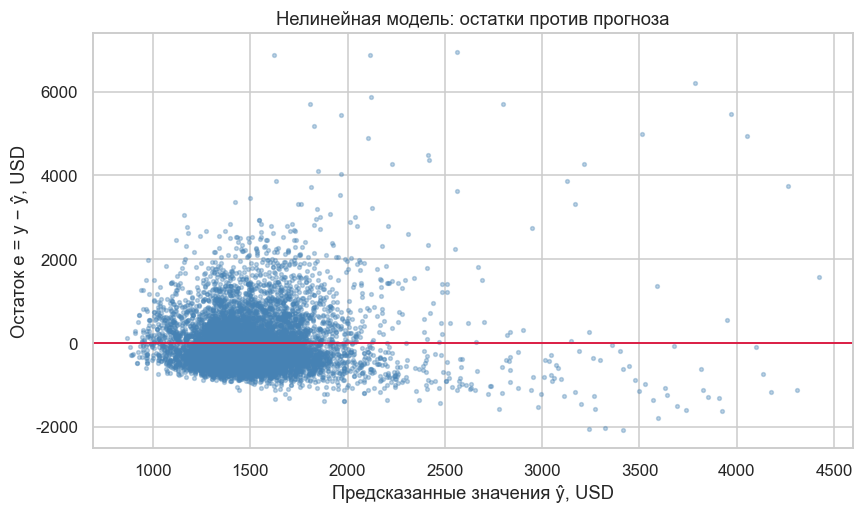

,среднее e,дисперсия e
"(843.13, 1337.669]",13.267860,340633.353390
"(1337.669, 1467.085]",-39.016113,336040.032415
"(1467.085, 1647.432]",-16.055749,428642.428762
"(1647.432, 4550.533]",41.872325,845807.014856


In [15]:
take_n = rng.choice(n, size=8000, replace=False)
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.scatter(fitted_nl[take_n], resid_nl[take_n], s=6, alpha=0.35, c="steelblue")
ax.axhline(0, color="crimson", lw=1.2)
ax.set_title("Нелинейная модель: остатки против прогноза")
ax.set_xlabel("Предсказанные значения ŷ, USD")
ax.set_ylabel("Остаток e = y − ŷ, USD")
fig.tight_layout()
plt.show()

q_n = pd.qcut(fitted_nl, 4, duplicates="drop")
g_n = pd.Series(resid_nl).groupby(q_n, observed=True)
quart_n = pd.DataFrame({"среднее e": g_n.mean(), "дисперсия e": g_n.var(ddof=1)})
display(quart_n)
sd_n = float(resid_nl.std(ddof=1))
max_abs_n = float(np.max(np.abs(quart_n["среднее e"])))
bp_lm_n, bp_p_n, _, _ = het_breuschpagan(resid_nl, nl.model.exog)
print(f"sd(e) = {sd_n:.2f}")
print(f"наибольший |средний e| = {max_abs_n:.2f}, отношение к sd = {max_abs_n / sd_n:.3f}")
print(f"max/min дисперсий = {quart_n['дисперсия e'].max() / quart_n['дисперсия e'].min():.4f}")
print(f"Бройш–Паган: LM = {bp_lm_n:.2f}, p = {bp_p_n:.3g}")


![график](../2LAB_MAD/figures/nb/10.png)

Облако визуально не отличается от графика 5: густое ядро около 1000–2000 USD, выбросы вверх на тысячи долларов, более широкий разброс справа. Групповые средние около +13, −39, −16, +42. Отношение к sd около 0,06. Отношение дисперсий около 2,52. Бройш–Паган по-прежнему отвергает постоянную дисперсию (LM около 4466, p-value = 0).

Нелинейные члены площади не убрали воронку. Пропущенная кривизна, правая учебная схема, здесь не была главной проблемой. Главная — большой разброс цены, которого тремя функциями площади не объяснить.


## График 11. Стандартизированные остатки нелинейной модели

\[
e_i^{st} = \frac{e_i}{s_e}, \qquad s_e = sd(y - \hat y^{nl}).
\]

Красная кривая снова \(N(0, 1)\). Сравнивать этот рисунок нужно с графиком 6: если свёртка исправила форму ошибок, хвост должен стать короче, а столбец — ближе к красной кривой.


асимметрия = 2.1636
эксцесс = 9.8472


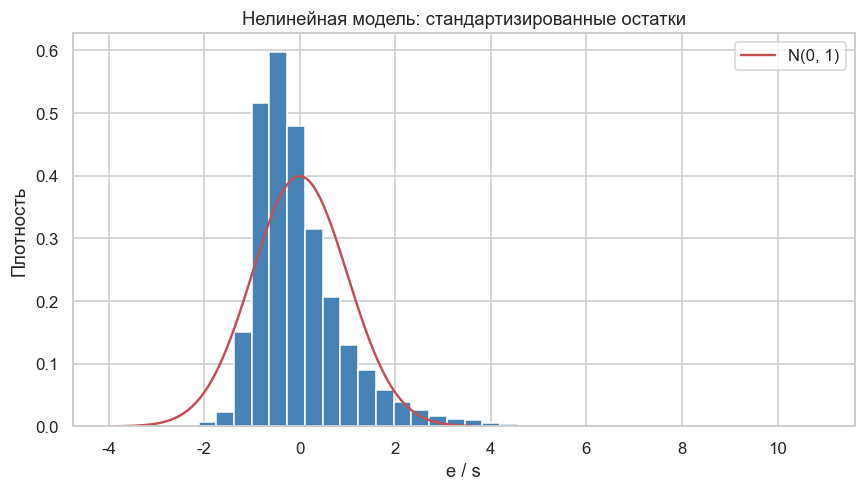

In [16]:
std_nl = resid_nl / resid_nl.std(ddof=1)
print(f"асимметрия = {pd.Series(std_nl).skew():.4f}")
print(f"эксцесс = {pd.Series(std_nl).kurtosis():.4f}")

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.hist(std_nl, bins=40, color="steelblue", edgecolor="white", density=True)
xs = np.linspace(-4, 8, 400)
ax.plot(xs, stats.norm.pdf(xs), "r-", lw=1.6, label="N(0, 1)")
ax.set_title("Нелинейная модель: стандартизированные остатки")
ax.set_xlabel("e / s")
ax.set_ylabel("Плотность")
ax.legend()
fig.tight_layout()
plt.show()


![график](../2LAB_MAD/figures/nb/11.png)

Асимметрия снова около 2,16, эксцесс около 9,85. Пик левее нуля, хвост вправо до 8–10 стандартных отклонений. От гистограммы линейной модели эта не отличается. Пункты 6–10 для нелинейной модели: уравнение значимо (\(F \approx 3588\), p-value = 0), \(R^2 = 0{,}153\) по-прежнему низкий, среднее остатков по уровню прогноза примерно постоянно, гомоскедастичность отвергается, нормальность остатков не выполняется.


## График 12. Линейная модель против нелинейной

Два столбца — обычный \(R^2\) МНК. Разница высот — это \(\Delta R^2 = R^2_{nl} - R^2_{lin}\), та же величина, что стоит в числителе вложенного F. Масштаб оси специально начинается с нуля, иначе прибавка в четвёртом знаке выглядит как «столбец вырос вдвое».


ΔR² = +0.000465
ΔRMSE = +0.1916 USD


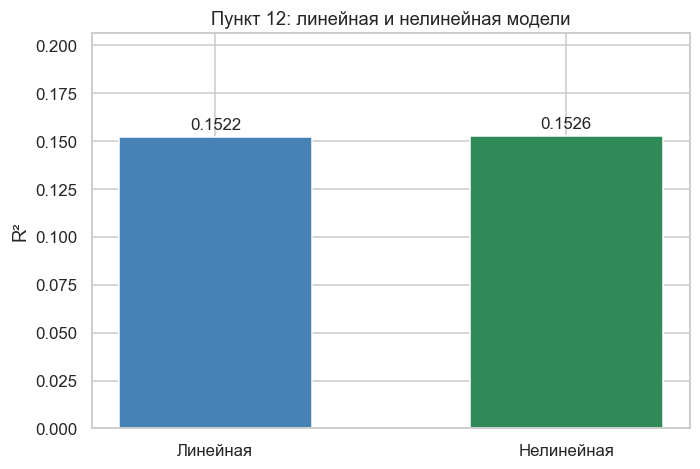

In [17]:
names_ln = ["Линейная", "Нелинейная"]
vals_ln = [float(lin.rsquared), float(nl.rsquared)]
fig, ax = plt.subplots(figsize=(6.5, 4.4))
bars = ax.bar(names_ln, vals_ln, color=["steelblue", "seagreen"], width=0.55)
ax.set_ylabel("R²")
ax.set_title("Пункт 12: линейная и нелинейная модели")
ax.set_ylim(0, max(vals_ln) * 1.35)
for bar, val in zip(bars, vals_ln):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 0.004, f"{val:.4f}", ha="center")
fig.tight_layout()
plt.show()
print(f"ΔR² = {nl.rsquared - lin.rsquared:+.6f}")
print(f"ΔRMSE = {rmse_lin - rmse_nl:+.4f} USD")


![график](../2LAB_MAD/figures/nb/12.png)

Столбцы почти одной высоты: 0,1522 и 0,1526. Прибавка 0,00046 не видна глазом, и это само по себе ответ. Формально вложенный F значим, практически RMSE улучшается на 19 центов при средней цене 1515 USD. Коэффициенты \(x\), \(x^2\) и \(x^2 \log x\) из-за VIF в тысячи не интерпретируются. Для содержательного вывода достаточно линейного уравнения пункта 5.


## График 13. Три модели вместе

После пункта 12 сравнение наконец можно показать на одном рисунке. Высота столбца — доля объяснённой дисперсии цены: у линейной и нелинейной это \(R^2\) МНК, у Пуассона — \(R^2_{var}\). Ось с нуля, чтобы 0,15 не выглядело как почти полное объяснение.


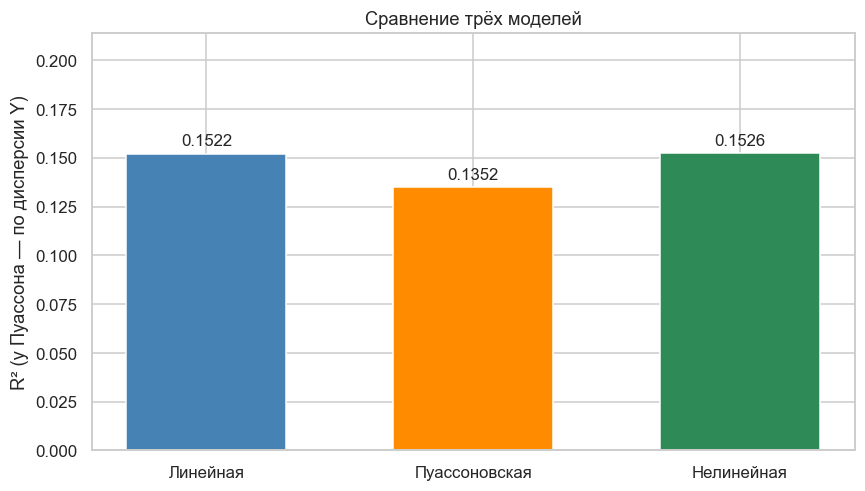

,модель,R2,R2_adj,RMSE
0,Линейная,0.152162,0.152137,699.102069
1,Пуассоновская,0.135155,0.135129,706.079277
2,Нелинейная,0.152627,0.152585,698.910424


In [18]:
cmp = pd.DataFrame({
    "модель": ["Линейная", "Пуассоновская", "Нелинейная"],
    "R2": [float(lin.rsquared), float(r2_pois), float(nl.rsquared)],
    "R2_adj": [float(lin.rsquared_adj), float(r2_pois_adj), float(nl.rsquared_adj)],
    "RMSE": [rmse_lin, rmse_pois, rmse_nl],
})
display(cmp)

fig, ax = plt.subplots(figsize=(8, 4.6))
bars = ax.bar(cmp["модель"], cmp["R2"], color=["steelblue", "darkorange", "seagreen"], width=0.6)
ax.set_ylabel("R² (у Пуассона — по дисперсии Y)")
ax.set_title("Сравнение трёх моделей")
ax.set_ylim(0, float(cmp["R2"].max()) * 1.4)
for bar, val in zip(bars, cmp["R2"]):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 0.004, f"{val:.4f}", ha="center")
fig.tight_layout()
plt.show()


![график](../2LAB_MAD/figures/nb/13.png)

Зелёный столбец чуть выше синего, оранжевый ниже обоих. Все три сидят около 0,14–0,15 при шкале до 1. Усложнение распределения (Пуассон) качество снижает. Усложнение формы по площади (зелёный столбец) качество почти не меняет.

Итоговая модель для защиты — линейная:

\[
\hat y = 757{,}30 - 74{,}86 \cdot bedrooms + 0{,}955 \cdot square\_feet - 59{,}54 \cdot pets\_yes.
\]

Площадь входит с плюсом, около 0,96 USD за квадратный фут. Дополнительная спальня при той же площади — с минусом около 75 USD, потому что площадь дробится на большее число комнат; безусловная средняя цена при этом с числом спален растёт. Разрешение животных связано с ценой ниже примерно на 60 USD. Это условные средние по объявлениям, не причинный эффект. Свободный член ценой реальной квартиры не является: площади 0 в данных нет.

Все три уравнения статистически значимы при \(n = 99602\). Ограничение работы — состав признаков, а не формула связи: город, район, состояние квартиры и срок сдачи в \(X\) не входят, поэтому \(R^2\) около 0,15.


## Короткие ответы, если спросят по графику

**Почему минус у спален, хотя на гистограмме двушки должны быть дороже.** На гистограмме спален видно, что сравнение идёт в основном между 1 и 2. Двушки в среднем больше по площади. В уравнении площадь уже стоит отдельным слагаемым, и при фиксированных футах лишняя комната связана с ценой ниже.

**Какой график остатков был бы хорошим.** Левая схема графика 4: полоса одной ширины вокруг нуля. Наш график 5 — воронка. График 6 это подтверждает длинным правым хвостом.

**Почему Пуассон не выиграл, хотя столбцы целые.** График 9 ниже у Пуассона, график 7 не стал ровнее графика 5, \(\varphi = 307\) вместо 1. Целые доллары не делают плату счётчиком событий.

**Зачем нелинейная модель, если зелёный столбец едва выше синего.** Задание просит её построить. Графики 10 и 11 показывают, что остатки не исправились. Прибавка \(R^2\) на графике 12 равна 0,0005. Коэффициенты кривизны не читаются из-за коллинеарности.

**Значима ли модель, если \(R^2\) низкий.** Да. F отвечает на вопрос «есть ли связь», \(R^2\) — на вопрос «какую долю разброса она снимает». При таком n связь по площади находится надёжно и объясняет только 15% цены.
